# Read and Write MATLAB Files with `load_matfile` and `save_matfile`

Many electrophysiology and behavior pipelines produce MATLAB `.mat` files. `braintools.file` wraps `scipy.io` so that MATLAB data arrives as ordinary Python objects:

| MATLAB | Python after `load_matfile` |
|---|---|
| numeric / char matrix | NumPy array (`1 x 1` becomes a Python scalar, `1 x N` a 1-D array) |
| char row vector | `str` |
| struct | `dict` |
| struct array | `list` of `dict` |
| cell array | `list` (nested for 2-D cells) |
| logical | `uint8` array (or `int` scalar) |

`save_matfile` goes the other way, writing a Python dict to a MATLAB 5 `.mat` file atomically, via a temporary file and a rename.

This tutorial builds a small experiment file, loads it, analyzes it, and writes results back.

## 1. Setup

All files go to a temporary directory that is removed at the end.

In [1]:
import shutil
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio

from braintools.file import load_matfile, save_matfile

workdir = Path(tempfile.mkdtemp(prefix="braintools_mat_"))
rng = np.random.default_rng(0)
print("files go to a temporary directory")

files go to a temporary directory


## 2. Writing a `.mat` File

`save_matfile(filename, data)` accepts the same values as `scipy.io.savemat`, and the Python type decides the MATLAB type that is written:

- `dict` becomes a struct, and a list of dicts becomes a struct array;
- a NumPy array of `dtype=object`, or a list of arrays with different lengths, becomes a cell array;
- numbers, `bool`, and numeric arrays become numeric matrices.

The file below mimics a recording session: session metadata, a struct array with one entry per trial (each with its own spike times), and the condition names as a cell array.

In [2]:
n_trials = 12
conditions = np.array(["low", "medium", "high"], dtype=object)  # object array -> cell array
rates_hz = {"low": 5.0, "medium": 15.0, "high": 30.0}

trials = []
for trial_id in range(n_trials):
    condition = conditions[trial_id % 3]
    n_spikes = rng.poisson(rates_hz[condition] * 2.0)  # 2-second trials
    trials.append({
        "id": trial_id + 1,
        "condition": condition,
        "spike_times": np.sort(rng.uniform(0.0, 2.0, n_spikes)),
        "correct": bool(rng.random() < 0.8),
    })

session = {
    "session_info": {"subject": "M042", "date": "2026-03-14", "sampling_rate": 30000.0},
    "conditions": conditions,
    "trials": trials,  # list of dicts -> struct array
    "lfp": rng.standard_normal((4, 2000)),  # 4 channels x 2000 samples
}

session_file = workdir / "session.mat"
save_matfile(session_file, session)
print(f"saved {session_file.name} ({session_file.stat().st_size} bytes)")

saved session.mat (72120 bytes)


## 3. Loading a `.mat` File

`load_matfile` returns a dict of the file's variables with MATLAB containers converted recursively. MATLAB's header entries (`__header__`, `__version__`, `__globals__`) are left out unless you pass `include_header=True`.

In [3]:
data = load_matfile(session_file)

print(f"variables: {list(data)}")
print(f"session_info: {data['session_info']}")
print(f"conditions:   {data['conditions']}  ({type(data['conditions']).__name__})")
print(f"lfp:          {type(data['lfp']).__name__} {data['lfp'].shape}")
print()
print(f"trials: {type(data['trials']).__name__} of {len(data['trials'])} {type(data['trials'][0]).__name__}s")
first = data["trials"][0]
for key, value in first.items():
    print(f"  {key:12s} {type(value).__name__:8s} {value if not isinstance(value, np.ndarray) else value.shape}")

variables: ['session_info', 'conditions', 'trials', 'lfp']
session_info: {'subject': 'M042', 'date': '2026-03-14', 'sampling_rate': 30000.0}
conditions:   ['low', 'medium', 'high']  (list)
lfp:          ndarray (4, 2000)

trials: list of 12 dicts
  id           int      1
  condition    str      low
  spike_times  ndarray  (11,)
  correct      int      1


Note `correct`: MATLAB 5 files have no boolean type in `scipy.io`, so logical values come back as integers (`uint8` arrays, or `int` for a single value). Convert with `bool(...)` or `.astype(bool)` when you need booleans.

## 4. Analyzing the Loaded Data

Because structs are dicts and struct arrays are lists, ordinary Python is enough to work with the session. Here we compute the firing rate per trial and plot a raster sorted by condition.

low     mean rate   5.5 Hz over 4 trials (true 5 Hz)
medium  mean rate  14.5 Hz over 4 trials (true 15 Hz)
high    mean rate  29.4 Hz over 4 trials (true 30 Hz)
accuracy: 83%


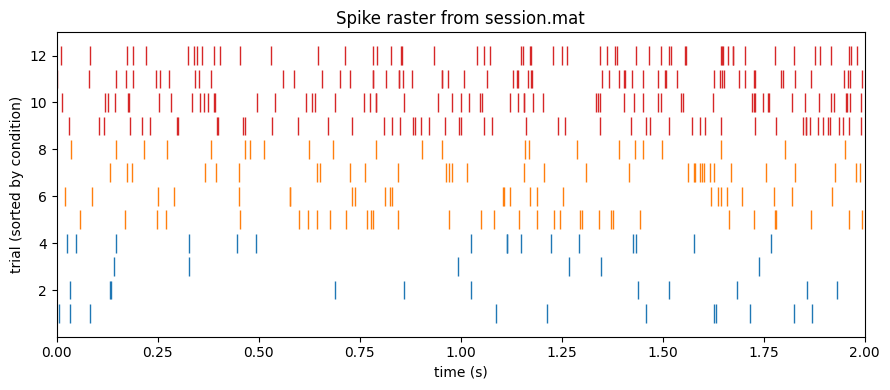

In [4]:
trial_duration = 2.0  # seconds
by_condition = {name: [] for name in data["conditions"]}
for trial in data["trials"]:
    spikes = np.atleast_1d(trial["spike_times"])  # a single spike would load as a scalar
    by_condition[trial["condition"]].append(spikes.size / trial_duration)

for name, rates in by_condition.items():
    print(f"{name:7s} mean rate {np.mean(rates):5.1f} Hz over {len(rates)} trials (true {rates_hz[name]:.0f} Hz)")

accuracy = np.mean([bool(trial["correct"]) for trial in data["trials"]])
print(f"accuracy: {accuracy:.0%}")

fig, ax = plt.subplots(figsize=(9, 4))
order = sorted(data["trials"], key=lambda t: list(data["conditions"]).index(t["condition"]))
colors = {"low": "tab:blue", "medium": "tab:orange", "high": "tab:red"}
for row, trial in enumerate(order):
    spikes = np.atleast_1d(trial["spike_times"])
    ax.vlines(spikes, row + 0.6, row + 1.4, color=colors[trial["condition"]], linewidth=1)
ax.set_xlabel("time (s)")
ax.set_ylabel("trial (sorted by condition)")
ax.set_title("Spike raster from session.mat")
ax.set_xlim(0, trial_duration)
plt.tight_layout()
plt.show()

The `np.atleast_1d` guard matters: with the default `squeeze_me=True`, a trial with exactly one spike stores a `1 x 1` matrix, which loads as a plain float rather than an array.

## 5. Options: `squeeze_me` and `struct_as_record`

Both defaults are chosen to give the natural Python structure above. Extra keyword arguments are passed through to `scipy.io.loadmat`.

- `squeeze_me=False` keeps MATLAB's 2-D shapes: scalars become `(1, 1)` arrays, strings become 1-element arrays, and even a single struct becomes a nested list (a `1 x 1` struct array). Use it only when you need the exact MATLAB shapes.
- `struct_as_record=True` returns structs as NumPy record arrays instead of dicts.

In [5]:
unsqueezed = load_matfile(session_file, squeeze_me=False)
info = unsqueezed["session_info"]
print(f"squeeze_me=False: session_info is {type(info).__name__} -> {type(info[0]).__name__} -> {type(info[0][0]).__name__}")
print(f"                  sampling_rate shape: {info[0][0]['sampling_rate'].shape}")

as_record = load_matfile(session_file, struct_as_record=True)
record = as_record["session_info"]
print(f"struct_as_record=True: {type(record).__name__} with fields {record.dtype.names}")

squeeze_me=False: session_info is list -> list -> dict
                  sampling_rate shape: (1, 1)
struct_as_record=True: ndarray with fields ('subject', 'date', 'sampling_rate')


## 6. Pitfalls When Writing

Because MATLAB types are chosen from the Python value, a few round trips are not exact:

| Written from Python | Read back |
|---|---|
| list of strings `['left', 'right']` | char matrix: NumPy array of strings **padded with spaces** to equal length |
| object array of strings | cell array: `list` of clean strings |
| `True` / bool array | `1` / `uint8` array |
| `None` | cannot be written: `save_matfile` raises `ValueError` and leaves any existing file untouched |

Use `np.array([...], dtype=object)` for lists of strings that must stay separate.

In [6]:
pitfalls_file = workdir / "pitfalls.mat"
save_matfile(pitfalls_file, {
    "as_list": ["left", "right", "up"],
    "as_cell": np.array(["left", "right", "up"], dtype=object),
    "flag": True,
})
pitfalls = load_matfile(pitfalls_file)
print(f"list of str  -> {pitfalls['as_list']!r}")
print(f"object array -> {pitfalls['as_cell']!r}")
print(f"True         -> {pitfalls['flag']!r}")

try:
    save_matfile(pitfalls_file, {"missing": None})
except ValueError:
    print("None         -> ValueError; existing file still loads:", list(load_matfile(pitfalls_file)))

list of str  -> array(['left ', 'right', 'up   '], dtype='<U5')
object array -> ['left', 'right', 'up']
True         -> 1
None         -> ValueError; existing file still loads: ['as_list', 'as_cell', 'flag']


## 7. Header Information and Errors

`include_header=True` adds MATLAB's header entries. A missing file raises `FileNotFoundError`. MATLAB **v7.3** files are HDF5 containers that `scipy.io` cannot read; `load_matfile` detects them and raises `NotImplementedError` pointing to HDF5 readers such as `h5py` or `mat73`. Save from MATLAB with `save(..., '-v7')` to stay compatible.

In [7]:
with_header = load_matfile(session_file, include_header=True)
print(f"header keys: {[k for k in with_header if k.startswith('__')]}")
print(f"version:     {with_header['__version__']}")

try:
    load_matfile(workdir / "no_such_file.mat")
except FileNotFoundError:
    print("missing file -> FileNotFoundError")

header keys: ['__header__', '__version__', '__globals__']
version:     1.0
missing file -> FileNotFoundError


## 8. Comparison with `scipy.io.loadmat`

`load_matfile` calls `scipy.io.loadmat(struct_as_record=False, squeeze_me=True)` and then converts SciPy's `mat_struct` objects and object arrays. With SciPy alone you navigate attributes and object arrays:

In [8]:
raw = sio.loadmat(session_file, struct_as_record=False, squeeze_me=True)
raw_trial = raw["trials"][0]
print(f"scipy:      trials is {type(raw['trials']).__name__} of {type(raw_trial).__name__}; "
      f"fields via attributes, e.g. raw_trial.condition = {raw_trial.condition!r}")
print(f"braintools: trials is list of dict; data['trials'][0]['condition'] = {data['trials'][0]['condition']!r}")

scipy:      trials is ndarray of mat_struct; fields via attributes, e.g. raw_trial.condition = 'low'
braintools: trials is list of dict; data['trials'][0]['condition'] = 'low'


## 9. Writing Results Back

Analysis results can be written back for colleagues using MATLAB. Nested dicts become nested structs.

In [9]:
results = {
    "analysis": {
        "conditions": np.array(data["conditions"], dtype=object),  # keep it a cell array
        "mean_rate_hz": np.array([np.mean(by_condition[c]) for c in data["conditions"]]),
        "accuracy": float(accuracy),
    }
}
results_file = workdir / "results.mat"
save_matfile(results_file, results)
print(load_matfile(results_file)["analysis"])

{'conditions': ['low', 'medium', 'high'], 'mean_rate_hz': array([ 5.5  , 14.5  , 29.375]), 'accuracy': 0.8333333333333334}


## 10. Clean Up

In [10]:
shutil.rmtree(workdir)
print("temporary directory removed")

temporary directory removed


## Summary

- `load_matfile` turns structs into dicts, struct arrays and cell arrays into lists, and leaves numeric data as NumPy arrays; keep the default `squeeze_me=True` for natural shapes and guard single-element arrays with `np.atleast_1d`.
- Logical values come back as integers; convert explicitly.
- `save_matfile` writes atomically; use object arrays for lists of strings, and avoid `None`.
- MATLAB v7.3 (HDF5) files need an HDF5 reader; `load_matfile` tells you so instead of failing obscurely.